In [1]:
"""
BirdWeather PUC & AirNow Luftqualitäts-Analyse (inkl. Lücken-Dokumentation)
===========================================================================
Dieses Skript verknüpft BirdWeather-PUC-Daten mit stündlichen AirNow-PM2.5-Werten,
dokumentiert Datenlücken beider Messsysteme lückenlos und schließt Ausfallzeiten
sauber aus, um Verzerrungen (z. B. falsche 0-Detektionen bei PUC-Ausfall) zu vermeiden.

Hauptfunktionen:
1. Einlesen der BirdWeather-PUC-Dateien & Unterscheidung zwischen "echten 0 Detections"
   (PUC aktiv, aber kein Vogel erkannt) und "PUC-Datenlücke" (PUC offline -> NaN).
2. Optionales Filtern der Detections nach Qualitätsmetriken (confidence, probability,
   score, certainty).
3. Einlesen der AirNow-CSV, Übersicht der Messstationen, Filterung nach AQSID und
   Diagnose der höchsten PM2.5-Werte / Ausreißer.
4. Automatische Dokumentation aller Datenlücken (Zusammenfassung, Lücken-Tabelle
   als DataFrame/CSV und visueller Verfügbarkeits-Zeitstrahl).
5. Bereinigte Visualisierungen (mit Markern für isolierte Werte nach Lücken) sowie
   unverzerrte Korrelations-, Tagesgang-, Lag- und Regressionsanalysen.
"""

%config InteractiveShell.cache_size = 3

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
import seaborn as sns
import statsmodels.api as sm
import gc


# =============================================================================
# 1. KONFIGURATION & FILTER-EINSTELLUNGEN
# =============================================================================
# Pfade anpassen:
DATA_DIR = Path("/home/tun/Projects/tuc/ML/birdweather/exploration")
AIRNOW_PATH = Path("/home/tun/Projects/tuc/ML/birdweather/exploration/airnow_data.csv")

# Optional: Pfad zum Exportieren der Lücken-Dokumentation (auf None setzen zum Deaktivieren)
EXPORT_GAPS_CSV = DATA_DIR / "datenluecken_dokumentation.csv"

# Gewünschte AirNow-Messstation (AQSID als String angeben, damit führende Nullen erhalten bleiben)
TARGET_AQSID = "410171001"

# -----------------------------------------------------------------------------
# Detection-Qualitätsfilter (BirdNET / BirdWeather)
# -----------------------------------------------------------------------------
FILTER_DETECTIONS = False
MIN_CONFIDENCE = 0.50    # BirdNET-Sicherheit (0.0 bis 1.0, None = aus)
MIN_PROBABILITY = None   # Saisonale/räumliche Wahrscheinlichkeit (0.0 bis 1.0, None = aus)
MIN_SCORE = None         # Kombinierter BirdWeather-Score (ca. 0 bis 10, None = aus)
ALLOWED_CERTAINTY = None # z. B. ["almost_certain", "very_likely"], None = aus

# -----------------------------------------------------------------------------
# Umgang mit Datenlücken & Ausreißern
# -----------------------------------------------------------------------------
# Maximale Lückenlänge (in Stunden), über die PUC-Sensoren interpoliert werden dürfen.
# 0 = keine Interpolation (empfohlen für unverfälschte Statistik); 1-2 = nur sehr kurze Lücken füllen.
MAX_SENSOR_INTERP_HOURS = 0

# Ab welcher Dauer (in Stunden) Lücken in der Detail-Tabelle aufgelistet werden sollen:
MIN_GAP_HOURS_TO_LOG = 2

# Optionaler Plausibilitäts-Filter für extreme AirNow-Sensorfehler (z. B. > 1000 µg/m³):
# Auf None setzen, um alle gültigen AirNow-Werte (>= 0) zu behalten.
MAX_PLAUSIBLE_PM25 = None

# Globale Plot-Einstellungen
pd.options.plotting.backend = "plotly"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [2]:
# =============================================================================
# 2. BIRDWEATHER PUC-DATEN EINLESEN & AKTIVE STUNDEN VS. LÜCKEN ERKENNEN
# =============================================================================
csv_files = [
    f for f in DATA_DIR.glob("*.csv")
    if f.resolve() != AIRNOW_PATH.resolve()
    and "airnow" not in f.name.lower()
    and "datenluecken" not in f.name.lower()
]
print(f"Gefundene BirdWeather-Dateien: {len(csv_files)}")

AUSCHLUSS_SPALTEN = {
    "datasource",
}

df_list = []
for file in csv_files:
    df_temp = pd.read_csv(file, usecols=lambda col: col.strip().lower() not in AUSCHLUSS_SPALTEN)
    df_temp["source_file"] = file.name
    df_list.append(df_temp)

if not df_list:
    raise FileNotFoundError(f"Keine BirdWeather-CSV-Dateien in {DATA_DIR} gefunden.")

# 1. Zusammenführen und Zwischenliste sofort freigeben
df = pd.concat(df_list, ignore_index=True)
del df_list
gc.collect()
print(f"Gesamtanzahl Rohzeilen (BirdWeather): {len(df)}")

# Spaltennamen vereinheitlichen & Duplikate entfernen (ohne zusätzliche .copy())
df.columns = df.columns.str.strip().str.lower()
df = df.loc[:, ~df.columns.duplicated()]

# 2. HIER KOMMEN DIE DTYPES-ÄNDERUNGEN REIN (vor Indexierung & Filtern):
#    a) Textspalten mit vielen Wiederholungen in 'category' umwandeln
if "certainty" in df.columns:
    df["certainty"] = df["certainty"].astype(str).str.strip().str.lower().astype("category")

for cat_col in ["commonname", "scientificname", "source_file"]:
    if cat_col in df.columns:
        df[cat_col] = df[cat_col].astype("category")

#    b) Alle 64-Bit-Zahlen (Sensoren, Koordinaten, Scores) auf 32-Bit halbieren
float64_cols = df.select_dtypes(include=["float64"]).columns
df[float64_cols] = df[float64_cols].astype("float32")

int64_cols = df.select_dtypes(include=["int64"]).columns
df[int64_cols] = df[int64_cols].astype("int32")

# Zeitstempel robust als UTC parsen und chronologisch sortieren
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)
df = df.dropna(subset=["timestamp"]).sort_values("timestamp")
df_indexed = df.set_index("timestamp")
del df
gc.collect()

# Qualitätsmetriken konvertieren (direkt als float32 belassen)
quality_num_cols = [c for c in ["confidence", "probability", "score"] if c in df_indexed.columns]
for col in quality_num_cols:
    df_indexed[col] = pd.to_numeric(df_indexed[col], errors="coerce").astype("float32")

# -----------------------------------------------------------------------------
# WICHTIG: PUC-Aktivitätsstatus pro Stunde bestimmen (verhindert falsche 0-Werte!)
# -----------------------------------------------------------------------------
# Der PUC schreibt regelmäßig Umweltdaten/Logs, auch wenn kein Vogel singt.
# Stunden mit mindestens 1 Rohdatensatz = PUC war aktiv ("echte 0", falls kein Vogel).
# Stunden mit 0 Rohdatensätzen = PUC war offline / Datenlücke -> detections = NaN!
puc_raw_counts = df_indexed.resample("1h").size().rename("puc_raw_rows")
puc_active_hourly = (puc_raw_counts > 0).rename("puc_active")

# 2a. Vogelerkennungen vorbereiten & optional nach Qualitätskriterien filtern
df_detections = df_indexed[df_indexed["commonname"].notna()].copy()
total_detections_unfiltered = len(df_detections)

if quality_num_cols:
    print("\n--- Übersicht der Detection-Qualitätsmetriken (ungefiltert) ---")
    print(df_detections[quality_num_cols].describe().round(3))

if "certainty" in df_detections.columns:
    print("\n--- Verteilung 'certainty' (ungefiltert) ---")
    print(df_detections["certainty"].value_counts(dropna=False))

active_filter_labels = []
if FILTER_DETECTIONS:
    mask = pd.Series(True, index=df_detections.index)
    if MIN_CONFIDENCE is not None and "confidence" in df_detections.columns:
        mask &= df_detections["confidence"] >= MIN_CONFIDENCE
        active_filter_labels.append(f"conf>={MIN_CONFIDENCE}")
    if MIN_PROBABILITY is not None and "probability" in df_detections.columns:
        mask &= df_detections["probability"] >= MIN_PROBABILITY
        active_filter_labels.append(f"prob>={MIN_PROBABILITY}")
    if MIN_SCORE is not None and "score" in df_detections.columns:
        mask &= df_detections["score"] >= MIN_SCORE
        active_filter_labels.append(f"score>={MIN_SCORE}")
    if ALLOWED_CERTAINTY is not None and "certainty" in df_detections.columns:
        allowed_lower = [c.strip().lower() for c in ALLOWED_CERTAINTY]
        mask &= df_detections["certainty"].isin(allowed_lower)
        active_filter_labels.append(f"certainty in {allowed_lower}")
    df_detections = df_detections[mask]

filter_suffix = f"Filter: {', '.join(active_filter_labels)}" if active_filter_labels else "alle Detections"
kept_pct = (len(df_detections) / total_detections_unfiltered * 100) if total_detections_unfiltered > 0 else 0
print(
    f"\nVerwendete Detections ({filter_suffix}): "
    f"{len(df_detections)} von {total_detections_unfiltered} ({kept_pct:.1f}%)"
)

# Stündliche Detections zählen und auf das vollständige Stundenraster reindizieren
detections_hourly = (
    df_detections["commonname"]
    .resample("1h")
    .count()
    .reindex(puc_active_hourly.index, fill_value=0)
    .rename("detections")
)

# Stunden, in denen der PUC komplett offline war, explizit auf NaN setzen (statt 0!)
detections_hourly = detections_hourly.where(puc_active_hourly, other=np.nan)

# 2b. PUC-Umwelt- und Spektralsensoren auf 1h-Mittelwerte resampeln
all_sensor_candidates = [
    "voc", "eco2", "aqi", "soundpressurelevel",
    "clear", "nir",
    "f1", "f2", "f3", "f4", "f5", "f6", "f7", "f8"
]
sensor_cols = [c for c in all_sensor_candidates if c in df_indexed.columns]

sensors_hourly = df_indexed[sensor_cols].resample("1h").mean().reindex(puc_active_hourly.index)
if MAX_SENSOR_INTERP_HOURS > 0:
    sensors_hourly = sensors_hourly.interpolate(method="time", limit=MAX_SENSOR_INTERP_HOURS)

# Stündlichen PUC-DataFrame zusammenführen
df_hourly = pd.concat([puc_active_hourly, puc_raw_counts, detections_hourly, sensors_hourly], axis=1)

# Rohdaten nach der 1h-Aggregation vollständig aus dem RAM entfernen
del df_indexed, df_detections
gc.collect()

Gefundene BirdWeather-Dateien: 3
Gesamtanzahl Rohzeilen (BirdWeather): 3969950

--- Übersicht der Detection-Qualitätsmetriken (ungefiltert) ---
        confidence  probability        score
count  1017124.000  1017124.000  1017124.000
mean         0.722        0.333        7.588
std          0.142        0.135        0.680
min          0.500        0.050        4.368
25%          0.597        0.277        7.132
50%          0.711        0.309        7.599
75%          0.841        0.387        8.047
max          1.000        0.994        9.860

--- Verteilung 'certainty' (ungefiltert) ---
certainty
almost_certain    1017124
nan                     0
Name: count, dtype: int64

Verwendete Detections (alle Detections): 1017124 von 1017124 (100.0%)


0

In [3]:
# =============================================================================
# 3. AIRNOW-CSV EINLESEN, NACH AQSID FILTERN & MIT PUC-DATEN VERKNÜPFEN
# =============================================================================
df_airnow_raw = pd.read_csv(AIRNOW_PATH, dtype={"AQSID": str})
df_airnow_raw.columns = df_airnow_raw.columns.str.strip()
df_airnow_raw["AQSID"] = df_airnow_raw["AQSID"].str.strip()

stations_overview = (
    df_airnow_raw.groupby(["AQSID", "SiteName", "Parameter", "Unit"], dropna=False)["Value"]
    .agg(anzahl_werte="count", min_wert="min", max_wert="max")
    .reset_index()
)
print("\n--- Verfügbare AirNow-Messstationen in der Datei ---")
print(stations_overview.to_string(index=False))

df_station = df_airnow_raw[df_airnow_raw["AQSID"] == TARGET_AQSID].copy()
if df_station.empty:
    available_ids = df_airnow_raw["AQSID"].dropna().unique().tolist()
    raise ValueError(f"AQSID '{TARGET_AQSID}' nicht gefunden. Verfügbar: {available_ids}")

station_name = df_station["SiteName"].dropna().iloc[0] if "SiteName" in df_station.columns else TARGET_AQSID

# Zeitstempel in UTC parsen & ungültige AirNow-Werte (< 0, z. B. -999) bereinigen
df_station["timestamp"] = pd.to_datetime(df_station["UTC"], errors="coerce", utc=True)
df_station["Value"] = pd.to_numeric(df_station["Value"], errors="coerce")
df_station.loc[df_station["Value"] < 0, "Value"] = np.nan
if MAX_PLAUSIBLE_PM25 is not None:
    df_station.loc[df_station["Value"] > MAX_PLAUSIBLE_PM25, "Value"] = np.nan

df_station = df_station.dropna(subset=["timestamp"])

# Long-to-Wide-Transformation
df_airnow_wide = df_station.pivot_table(
    index="timestamp",
    columns="Parameter",
    values="Value",
    aggfunc="mean"
)

df_airnow_wide.columns = (
    df_airnow_wide.columns.str.strip()
    .str.lower()
    .str.replace(".", "", regex=False)
    .str.replace(" ", "_", regex=False)
)

df_airnow_wide = df_airnow_wide.resample("1h").mean()

# Lückenloses stündliches Gesamt-Raster (Left Join auf das vollständige PUC-Zeitraster)
df_merged = df_hourly.join(df_airnow_wide, how="left")
df_merged["puc_active"] = df_merged["puc_active"].fillna(False)
df_merged["airnow_active"] = df_merged["pm25"].notna() if "pm25" in df_merged.columns else False
df_merged["both_valid"] = df_merged["puc_active"] & df_merged["airnow_active"]

# Diagnose: Die 10 höchsten PM2.5-Werte im Zeitraum ausgeben (erklärt Y-Achsen-Skalierung!)
if "pm25" in df_merged.columns:
    print("\n--- Top 10 höchste AirNow PM2.5-Stundenwerte im PUC-Zeitraum ---")
    top_pm25 = df_merged.nlargest(10, "pm25")[["pm25", "detections", "puc_active"]]
    print(top_pm25.to_string())


--- Verfügbare AirNow-Messstationen in der Datei ---
    AQSID             SiteName Parameter  Unit  anzahl_werte  min_wert  max_wert
410130100 Prineville - Davidso     PM2.5 UG/M3         24701       0.0     449.2
410170004 Sisters Forest Servi     PM2.5 UG/M3         22004       0.0     529.0
410171001  Redmond High School     PM2.5 UG/M3         23734       1.7     189.2

--- Top 10 höchste AirNow PM2.5-Stundenwerte im PUC-Zeitraum ---
                            pm25  detections  puc_active
timestamp                                               
2024-07-29 01:00:00+00:00  189.2       131.0        True
2026-07-23 00:00:00+00:00  188.6        42.0        True
2026-07-23 16:00:00+00:00  172.2        94.0        True
2026-07-23 04:00:00+00:00  169.2         0.0        True
2026-07-23 17:00:00+00:00  165.3        79.0        True
2026-07-23 03:00:00+00:00  160.6         4.0        True
2026-07-23 07:00:00+00:00  152.1         0.0        True
2026-07-23 06:00:00+00:00  151.8         0.

In [4]:
# =============================================================================
# 4. DATENLÜCKEN DOKUMENTIEREN & VISUALISIEREN
# =============================================================================
def extract_gap_periods(is_valid_series: pd.Series, system_name: str) -> pd.DataFrame:
    """Identifiziert zusammenhängende Datenlücken (False-Blöcke) mit Start, Ende und Dauer."""
    is_gap = ~is_valid_series.fillna(False)
    block_ids = (is_gap != is_gap.shift()).cumsum()

    gaps = []
    for _, group in is_gap.groupby(block_ids):
        if group.iloc[0]:  # Nur Blöcke betrachten, in denen Daten fehlen
            start_ts = group.index[0]
            end_ts = group.index[-1]
            duration_h = len(group)
            gaps.append({
                "System": system_name,
                "Start (UTC)": start_ts,
                "Ende (UTC)": end_ts,
                "Dauer (Stunden)": duration_h,
                "Dauer (Tage)": round(duration_h / 24, 2)
            })
    return pd.DataFrame(gaps)


gaps_puc = extract_gap_periods(df_merged["puc_active"], "BirdWeather PUC")
gaps_airnow = extract_gap_periods(df_merged["airnow_active"], f"AirNow ({station_name})")
gaps_combined = extract_gap_periods(df_merged["both_valid"], "Gesamt (PUC oder AirNow fehlt)")

df_all_gaps = pd.concat([gaps_puc, gaps_airnow], ignore_index=True)
if not df_all_gaps.empty:
    df_all_gaps = df_all_gaps.sort_values(["Start (UTC)", "System"]).reset_index(drop=True)

# 4a. Zusammenfassung der Datenabdeckung ausgeben
total_hours = len(df_merged)
puc_valid_h = int(df_merged["puc_active"].sum())
airnow_valid_h = int(df_merged["airnow_active"].sum())
both_valid_h = int(df_merged["both_valid"].sum())

coverage_summary = pd.DataFrame([
    {
        "Datensatz": "Gesamtzeitraum (1h-Raster)",
        "Gültige Stunden": total_hours,
        "Fehlende Stunden": 0,
        "Abdeckung (%)": 100.0,
        "Anzahl Lücken (>=1h)": 0,
        "Längste Lücke (h)": 0
    },
    {
        "Datensatz": "BirdWeather PUC",
        "Gültige Stunden": puc_valid_h,
        "Fehlende Stunden": total_hours - puc_valid_h,
        "Abdeckung (%)": round(puc_valid_h / total_hours * 100, 1),
        "Anzahl Lücken (>=1h)": len(gaps_puc),
        "Längste Lücke (h)": int(gaps_puc["Dauer (Stunden)"].max()) if not gaps_puc.empty else 0
    },
    {
        "Datensatz": f"AirNow PM2.5 ({TARGET_AQSID})",
        "Gültige Stunden": airnow_valid_h,
        "Fehlende Stunden": total_hours - airnow_valid_h,
        "Abdeckung (%)": round(airnow_valid_h / total_hours * 100, 1),
        "Anzahl Lücken (>=1h)": len(gaps_airnow),
        "Längste Lücke (h)": int(gaps_airnow["Dauer (Stunden)"].max()) if not gaps_airnow.empty else 0
    },
    {
        "Datensatz": "Schnittmenge (Beide gültig -> Analysebasis)",
        "Gültige Stunden": both_valid_h,
        "Fehlende Stunden": total_hours - both_valid_h,
        "Abdeckung (%)": round(both_valid_h / total_hours * 100, 1),
        "Anzahl Lücken (>=1h)": len(gaps_combined),
        "Längste Lücke (h)": int(gaps_combined["Dauer (Stunden)"].max()) if not gaps_combined.empty else 0
    }
])

print("\n--- Dokumentation: Datenabdeckung & Lücken-Statistik ---")
print(coverage_summary.to_string(index=False))

if not df_all_gaps.empty:
    df_major_gaps = df_all_gaps[df_all_gaps["Dauer (Stunden)"] >= MIN_GAP_HOURS_TO_LOG]
    print(f"\n--- Detail-Liste aller Datenlücken >= {MIN_GAP_HOURS_TO_LOG} Stunden ({len(df_major_gaps)} Lücken) ---")
    print(df_major_gaps.to_string(index=False))

    if EXPORT_GAPS_CSV is not None:
        df_all_gaps.to_csv(EXPORT_GAPS_CSV, index=False)
        print(f"Vollständige Lücken-Dokumentation gespeichert unter: {EXPORT_GAPS_CSV}")

# 4b. Visueller Verfügbarkeits-Zeitstrahl (zeigt Ausfallzeiträume auf einen Blick)
df_avail = pd.DataFrame({
    "timestamp": df_merged.index,
    "1. BirdWeather PUC": np.where(df_merged["puc_active"], 1, np.nan),
    "2. AirNow PM2.5": np.where(df_merged["airnow_active"], 2, np.nan),
    "3. Beide gültig (Analysebasis)": np.where(df_merged["both_valid"], 3, np.nan),
})
df_avail_melted = df_avail.melt(id_vars="timestamp", var_name="System", value_name="Status")

fig_gaps = px.line(
    df_avail_melted,
    x="timestamp",
    y="Status",
    color="System",
    markers=True,
    title="Dokumentation der Datenverfügbarkeit & Lücken (Unterbrechungen = Datenausfall)",
    labels={"timestamp": "Zeit (UTC)", "Status": ""}
)
fig_gaps.update_traces(marker=dict(size=3), line=dict(width=4))
fig_gaps.update_yaxes(
    tickvals=[1, 2, 3],
    ticktext=["BirdWeather PUC", "AirNow PM2.5", "Beide gültig"],
    range=[0.5, 3.5]
)
fig_gaps.update_xaxes(rangeslider_visible=True)
fig_gaps.show()


--- Dokumentation: Datenabdeckung & Lücken-Statistik ---
                                  Datensatz  Gültige Stunden  Fehlende Stunden  Abdeckung (%)  Anzahl Lücken (>=1h)  Längste Lücke (h)
                 Gesamtzeitraum (1h-Raster)            21972                 0          100.0                     0                  0
                            BirdWeather PUC            21297               675           96.9                    26                535
                   AirNow PM2.5 (410171001)            20954              1018           95.4                   301                 88
Schnittmenge (Beide gültig -> Analysebasis)            20290              1682           92.3                   319                535

--- Detail-Liste aller Datenlücken >= 2 Stunden (134 Lücken) ---
                      System               Start (UTC)                Ende (UTC)  Dauer (Stunden)  Dauer (Tage)
AirNow (Redmond High School) 2024-06-18 13:00:00+00:00 2024-06-18 14:00:00+00:00         

In [5]:
# =============================================================================
# 5. GRAFISCHE EXPLORATION (MIT MARKERN FÜR ISOLIERTE WERTE NACH LÜCKEN)
# =============================================================================
df_p = df_merged.reset_index()

# 5a. Synchronisierter Facet-Plot mit Markern (macht auch isolierte 1h-Peaks sichtbar!)
facet_candidates = ["detections", "pm25", "aqi", "voc", "eco2", "soundpressurelevel"]
plot_cols = [c for c in facet_candidates if c in df_p.columns]

df_melted = df_p.melt(
    id_vars=["timestamp"],
    value_vars=plot_cols,
    var_name="Metrik",
    value_name="Wert"
)

fig_facet = px.line(
    df_melted,
    x="timestamp",
    y="Wert",
    facet_row="Metrik",
    color="Metrik",
    markers=True,  # Wichtig: Zeigt auch Einzelstunden an, die von NaN-Lücken umgeben sind
    title=f"Zeitreihenvergleich ({filter_suffix}): Vogelaktivität, PM2.5 ({station_name}) & PUC-Sensoren",
    height=230 * len(plot_cols)
)
fig_facet.update_traces(marker=dict(size=3), line=dict(width=1.2))
fig_facet.update_yaxes(matches=None)
fig_facet.update_xaxes(rangeslider_visible=True, row=len(plot_cols), col=1)
fig_facet.show()

# 5b. Detail-Ansicht für PM2.5 (99%-Quantil-Zoom vs. volle Skala mit Ausreißern)
if "pm25" in df_p.columns and df_p["pm25"].notna().any():
    q99_pm25 = df_p["pm25"].quantile(0.99)
    max_pm25 = df_p["pm25"].max()

    fig_pm25_zoom = px.line(
        df_p,
        x="timestamp",
        y="pm25",
        markers=True,
        title=f"AirNow PM2.5 Detailansicht (Y-Achse gezoomt bis 99%-Quantil: {q99_pm25:.1f} µg/m³ | Max: {max_pm25:.1f})",
        labels={"timestamp": "Zeit (UTC)", "pm25": "PM2.5 (µg/m³)"}
    )
    fig_pm25_zoom.update_traces(marker=dict(size=3.5), line=dict(width=1.3, color="#e74c3c"))
    fig_pm25_zoom.update_yaxes(range=[0, max(q99_pm25 * 1.15, 10)])
    fig_pm25_zoom.update_xaxes(rangeslider_visible=True)
    fig_pm25_zoom.show()

# 5c. Dual-Axis-Overlay: AirNow PM2.5 vs. PUC AQI (nur gültige Stunden)
if "pm25" in df_p.columns and "aqi" in df_p.columns:
    fig_dual = make_subplots(specs=[[{"secondary_y": True}]])
    fig_dual.add_trace(
        go.Scatter(
            x=df_p["timestamp"], y=df_p["pm25"],
            name="AirNow PM2.5 (µg/m³)", mode="lines+markers",
            marker=dict(size=3), line=dict(color="#e74c3c", width=1.5)
        ),
        secondary_y=False
    )
    fig_dual.add_trace(
        go.Scatter(
            x=df_p["timestamp"], y=df_p["aqi"],
            name="BirdWeather PUC AQI", mode="lines+markers",
            marker=dict(size=3), line=dict(color="#3498db", width=1.3), opacity=0.8
        ),
        secondary_y=True
    )
    fig_dual.update_layout(
        title=f"Direktvergleich: AirNow PM2.5 vs. PUC AQI ({station_name})",
        hovermode="x unified",
        template="plotly_white"
    )
    fig_dual.update_yaxes(title_text="AirNow PM2.5 (µg/m³)", secondary_y=False)
    fig_dual.update_yaxes(title_text="PUC AQI (Index)", secondary_y=True)
    fig_dual.show()


Analyse-Stichprobe (PUC aktiv): 21297 Stunden
Analyse-Stichprobe (PUC aktiv & AirNow PM2.5 gültig): 20290 Stunden


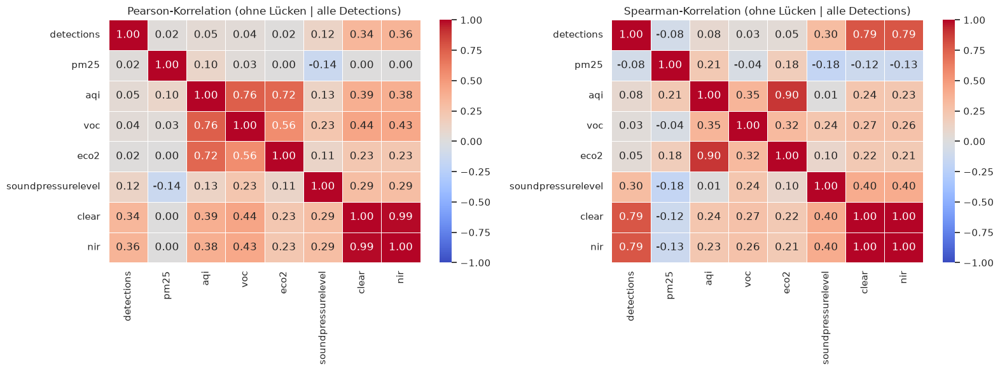


--- Paarweise Korrelationen (bereinigt um Datenlücken | alle Detections) ---
                             Paar  N (Stunden)  Pearson r  Pearson p  Spearman r  Spearman p  Signifikant (p<0.05)
              detections vs. pm25        20290      0.019     0.0066      -0.078      0.0000                  True
               detections vs. aqi        21275      0.051     0.0000       0.075      0.0000                  True
                     pm25 vs. aqi        20268      0.104     0.0000       0.215      0.0000                  True
               detections vs. voc        21275      0.035     0.0000       0.028      0.0001                  True
              detections vs. eco2        21275      0.015     0.0276       0.045      0.0000                  True
detections vs. soundpressurelevel        21275      0.118     0.0000       0.304      0.0000                  True
             detections vs. clear        21275      0.337     0.0000       0.786      0.0000                  True
  


--- Zeitversatz-Analyse: PM2.5 verzögert um 0-12h (exaktes Zeitraster | alle Detections) ---
 Lag (Stunden)  N (Stunden)  Spearman r  p-Wert  Signifikant (p<0.05)
             0        20290      -0.078  0.0000                  True
             1        20291      -0.044  0.0000                  True
             2        20293      -0.011  0.1241                 False
             3        20294       0.017  0.0152                  True
             4        20295       0.044  0.0000                  True
             5        20296       0.071  0.0000                  True
             6        20297       0.095  0.0000                  True
             7        20301       0.115  0.0000                  True
             8        20301       0.131  0.0000                  True
             9        20301       0.136  0.0000                  True
            10        20299       0.133  0.0000                  True
            11        20297       0.121  0.0000                  T

In [ ]:
# =============================================================================
# 6. UNVERZERRTE STATISTISCHE ANALYSE (NUR STUNDEN OHNE DATENLÜCKEN)
# =============================================================================
# Für alle Korrelationen und Regressionen wird streng auf Stunden gefiltert,
# in denen der PUC aktiv war (keine künstlichen 0-Werte aus Ausfallzeiten!).
df_puc_valid = df_merged[df_merged["puc_active"]].copy()
df_both_valid = df_merged[df_merged["both_valid"]].copy()

print(f"\nAnalyse-Stichprobe (PUC aktiv): {len(df_puc_valid)} Stunden")
print(f"Analyse-Stichprobe (PUC aktiv & AirNow PM2.5 gültig): {len(df_both_valid)} Stunden")

corr_candidates = [
    c for c in ["detections", "pm25", "aqi", "voc", "eco2", "soundpressurelevel", "clear", "nir"]
    if c in df_puc_valid.columns
]

# 6a. Korrelationsmatrizen (paarweise vollständige Fälle, ohne PUC-Ausfallstunden)
corr_pearson = df_puc_valid[corr_candidates].corr(method="pearson")
corr_spearman = df_puc_valid[corr_candidates].corr(method="spearman")

fig_hm, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(corr_pearson, ax=axes[0], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
axes[0].set_title(f"Pearson-Korrelation (ohne Lücken | {filter_suffix})")

sns.heatmap(corr_spearman, ax=axes[1], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
axes[1].set_title(f"Spearman-Korrelation (ohne Lücken | {filter_suffix})")

plt.tight_layout()
plt.show()

# 6b. Paarweise Korrelationen & Signifikanztests
focus_pairs = [
    ("detections", "pm25"),
    ("detections", "aqi"),
    ("pm25", "aqi"),
    ("detections", "voc"),
    ("detections", "eco2"),
    ("detections", "soundpressurelevel"),
    ("detections", "clear"),
    ("pm25", "voc"),
    ("pm25", "eco2"),
]

pair_results = []
for var_x, var_y in focus_pairs:
    if var_x in df_puc_valid.columns and var_y in df_puc_valid.columns:
        valid = df_puc_valid[[var_x, var_y]].dropna()
        if len(valid) > 10:
            r_p, p_p = stats.pearsonr(valid[var_x], valid[var_y])
            r_s, p_s = stats.spearmanr(valid[var_x], valid[var_y])
            pair_results.append({
                "Paar": f"{var_x} vs. {var_y}",
                "N (Stunden)": len(valid),
                "Pearson r": round(r_p, 3),
                "Pearson p": round(p_p, 4),
                "Spearman r": round(r_s, 3),
                "Spearman p": round(p_s, 4),
                "Signifikant (p<0.05)": p_s < 0.05
            })

print(f"\n--- Paarweise Korrelationen (bereinigt um Datenlücken | {filter_suffix}) ---")
print(pd.DataFrame(pair_results).to_string(index=False))

# 6c. Tagesrhythmus-kontrollierte Korrelation (stündlich 0-23 Uhr UTC, nur gültige Paare)
if "pm25" in df_both_valid.columns and not df_both_valid.empty:
    df_both_valid["hour"] = df_both_valid.index.hour
    hourly_pm25_corr = []

    for h in range(24):
        sub = df_both_valid[df_both_valid["hour"] == h][["detections", "pm25"]].dropna()
        if len(sub) > 5:
            r_s, p_s = stats.spearmanr(sub["detections"], sub["pm25"])
            hourly_pm25_corr.append({
                "hour": h,
                "spearman_r": r_s,
                "p_value": round(p_s, 4),
                "signifikant": p_s < 0.05,
                "n": len(sub)
            })

    df_hourly_pm25 = pd.DataFrame(hourly_pm25_corr)
    fig_hourly_corr = px.bar(
        df_hourly_pm25,
        x="hour",
        y="spearman_r",
        hover_data=["p_value", "n"],
        color="spearman_r",
        color_continuous_scale="RdBu",
        range_color=[-1, 1],
        title=f"Stundenweise Spearman-Korrelation: Detections vs. PM2.5 (ohne Lücken | {filter_suffix})",
        labels={"hour": "Uhrzeit (Stunde UTC)", "spearman_r": "Spearman r"}
    )
    fig_hourly_corr.add_hline(y=0, line_dash="dash", line_color="gray")
    fig_hourly_corr.update_xaxes(dtick=2)
    fig_hourly_corr.show()

    # 6d. Zeitversatz-Analyse (Lag 0 bis 12 Stunden)
    # Wichtig: .shift(lag) erfolgt auf dem LÜCKENLOSEN Stundenraster df_merged,
    # damit lag=1 immer exakt 1 echte Uhrstunde entspricht (und nicht über Ausfälle springt).
    lag_results = []
    for lag in range(0, 13):
        temp = pd.DataFrame({
            "detections": df_merged["detections"],
            "pm25_lagged": df_merged["pm25"].shift(lag)
        }).dropna()
        if len(temp) > 10:
            r_s, p_s = stats.spearmanr(temp["detections"], temp["pm25_lagged"])
            lag_results.append({
                "Lag (Stunden)": lag,
                "N (Stunden)": len(temp),
                "Spearman r": round(r_s, 3),
                "p-Wert": round(p_s, 4),
                "Signifikant (p<0.05)": p_s < 0.05
            })

    print(f"\n--- Zeitversatz-Analyse: PM2.5 verzögert um 0-12h (exaktes Zeitraster | {filter_suffix}) ---")
    print(pd.DataFrame(lag_results).to_string(index=False))

# 6e. Multivariate OLS-Regression (Listwise Deletion über alle gewählten Features)
# aqi entfernt, um Multikollinearität mit pm25 zu vermeiden
reg_features = [c for c in ["pm25", "aqi", "clear", "soundpressurelevel"] if c in df_puc_valid.columns]
if reg_features:
    data_reg = df_puc_valid[["detections"] + reg_features].dropna()
    if len(data_reg) > len(reg_features) + 5:
        X_clean = sm.add_constant(data_reg[reg_features])
        y_clean = data_reg["detections"]
        ols_model = sm.OLS(y_clean, X_clean).fit()
        print(f"\n--- Multivariate OLS-Regression (N={len(data_reg)} vollständige Stunden) ---")
        print(ols_model.summary())